# Phase 1: EDA & Problem Definition

## Project Objective
The objective is to analyze historical weather data and develop a machine learning system that predicts the next day's weather condition.

## Exploratory Data Analysis (EDA)
This phase includes dataset inspection, data cleaning, statistical analysis, and visualizations to understand weather patterns.

# Weather Forecasting ML System

## 1. Dataset Loading and Initial Inspection

This project uses historical weather data to analyze weather conditions and build machine learning models for weather prediction.

The notebook covers data preprocessing, exploratory data analysis (EDA), data visualization, supervised machine learning, and model evaluation. It also demonstrates weather prediction using the trained model.

## 2. Import Required Libraries

The following Python libraries are used for data manipulation, numerical operations, and weather data visualization.

- **Pandas:** Data loading and manipulation.
- **NumPy:** Numerical calculations.
- **Matplotlib:** Creating plots and charts.
- **Seaborn:** Statistical data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Dataset Loading and Initial Inspection

In this section, the weather dataset is loaded from a CSV file using Pandas. The `head()` function displays the first five rows to inspect the dataset's structure, column names, and sample values.

### 3.1 Dataset Structure and Information

The `info()` method provides an overview of the dataset, including the number of entries, column names, non-null values, data types, and memory usage. This helps us understand the dataset before performing data preprocessing.

In [2]:
df = pd.read_csv("../data/weather_data.csv", skiprows=2)

df.head()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
0,2021-01-01T00:00,16.7,76.0,0.0,0.0,1007.3,0.0,8.1
1,2021-01-01T01:00,16.2,77.0,0.0,0.0,1007.0,0.0,7.6
2,2021-01-01T02:00,16.2,75.0,0.0,0.0,1006.3,0.0,9.5
3,2021-01-01T03:00,16.0,74.0,0.0,0.0,1005.9,0.0,9.4
4,2021-01-01T04:00,15.8,74.0,0.0,0.0,1005.8,0.0,9.2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45651 entries, 0 to 45650
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   time                      45651 non-null  object 
 1   temperature_2m (°C)       45651 non-null  object 
 2   relative_humidity_2m (%)  43824 non-null  float64
 3   precipitation (mm)        43824 non-null  float64
 4   weather_code (wmo code)   43824 non-null  float64
 5   surface_pressure (hPa)    43824 non-null  float64
 6   cloud_cover (%)           43824 non-null  float64
 7   wind_speed_10m (km/h)     43824 non-null  float64
dtypes: float64(6), object(2)
memory usage: 2.8+ MB


### 3.2 Data Type Conversion

The dataset contains date and temperature values that need appropriate data types for analysis. The timestamp column is converted to a datetime format, and the temperature column is converted to numeric values to support further data processing.

In [4]:
df["time"] = pd.to_datetime(df["time"], errors="coerce")
df["temperature_2m (°C)"] = pd.to_numeric(
    df["temperature_2m (°C)"], errors="coerce"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45651 entries, 0 to 45650
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   time                      43824 non-null  datetime64[ns]
 1   temperature_2m (°C)       45650 non-null  float64       
 2   relative_humidity_2m (%)  43824 non-null  float64       
 3   precipitation (mm)        43824 non-null  float64       
 4   weather_code (wmo code)   43824 non-null  float64       
 5   surface_pressure (hPa)    43824 non-null  float64       
 6   cloud_cover (%)           43824 non-null  float64       
 7   wind_speed_10m (km/h)     43824 non-null  float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 2.8 MB


### 3.3 Inspection of Missing Timestamps

This step identifies rows with missing timestamps after converting the time column to datetime format. Inspecting these rows helps us understand data-quality issues and determine which records are suitable for the hourly weather forecasting analysis.

In [5]:
print("Missing timestamps:", df["time"].isna().sum())
print("\nRows with missing timestamps:")
display(df[df["time"].isna()].head(10))

Missing timestamps: 1827

Rows with missing timestamps:


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
43824,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43825,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
43826,NaT,3.0,NaN,NaN,NaN,NaN,NaN,NaN
43827,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
43828,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
43829,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
43830,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
43831,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
43832,NaT,3.0,NaN,NaN,NaN,NaN,NaN,NaN
43833,NaT,3.0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
raw_df = pd.read_csv("../data/weather_data.csv", skiprows=2)

print("First 5 original rows:")
display(raw_df.head())

print("\nRows around the missing timestamp section:")
display(raw_df.iloc[43820:43835])

print("\nLast 5 original rows:")
display(raw_df.tail())

First 5 original rows:


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
0,2021-01-01T00:00,16.7,76.0,0.0,0.0,1007.3,0.0,8.1
1,2021-01-01T01:00,16.2,77.0,0.0,0.0,1007.0,0.0,7.6
2,2021-01-01T02:00,16.2,75.0,0.0,0.0,1006.3,0.0,9.5
3,2021-01-01T03:00,16.0,74.0,0.0,0.0,1005.9,0.0,9.4
4,2021-01-01T04:00,15.8,74.0,0.0,0.0,1005.8,0.0,9.2



Rows around the missing timestamp section:


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
43820,2025-12-31T20:00,25.1,46.0,0.0,1.0,1004.6,25.0,4.9
43821,2025-12-31T21:00,24.2,49.0,0.0,1.0,1004.8,28.0,6.5
43822,2025-12-31T22:00,23.2,54.0,0.0,1.0,1005.4,37.0,6.8
43823,2025-12-31T23:00,22.4,58.0,0.0,2.0,1005.5,54.0,7.6
43824,time,weather_code (wmo code),NaN,NaN,NaN,NaN,NaN,NaN
43825,2021-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN
43826,2021-01-02,3,NaN,NaN,NaN,NaN,NaN,NaN
43827,2021-01-03,1,NaN,NaN,NaN,NaN,NaN,NaN
43828,2021-01-04,1,NaN,NaN,NaN,NaN,NaN,NaN
43829,2021-01-05,0,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 original rows:


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
45646,2025-12-27,0,NaN,NaN,NaN,NaN,NaN,NaN
45647,2025-12-28,0,NaN,NaN,NaN,NaN,NaN,NaN
45648,2025-12-29,1,NaN,NaN,NaN,NaN,NaN,NaN
45649,2025-12-30,0,NaN,NaN,NaN,NaN,NaN,NaN
45650,2025-12-31,2,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Total rows:", len(raw_df))

print("Rows with hourly data:", raw_df["relative_humidity_2m (%)"].notna().sum())

print("Rows with daily data:", raw_df["relative_humidity_2m (%)"].isna().sum())

print("\nColumn names:")
print(raw_df.columns.tolist())

Total rows: 45651
Rows with hourly data: 43824
Rows with daily data: 1827

Column names:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)', 'weather_code (wmo code)', 'surface_pressure (hPa)', 'cloud_cover (%)', 'wind_speed_10m (km/h)']


### 3.4 Extracting Hourly Weather Records

The original CSV file contains both hourly and daily weather records. The hourly records contain humidity values, while the daily records do not. This step selects the hourly records to create a dataset suitable for the subsequent weather analysis and machine learning process.

In [8]:
hourly_df = raw_df[raw_df["relative_humidity_2m (%)"].notna()].copy()

print("Hourly dataset shape:", hourly_df.shape)
print("\nMissing values in hourly data:")
print(hourly_df.isna().sum())

Hourly dataset shape: (43824, 8)

Missing values in hourly data:
time                        0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
weather_code (wmo code)     0
surface_pressure (hPa)      0
cloud_cover (%)             0
wind_speed_10m (km/h)       0
dtype: int64


In [9]:
df.tail(10)

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
45641,NaT,3.0,NaN,NaN,NaN,NaN,NaN,NaN
45642,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
45643,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45644,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45645,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45646,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45647,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45648,NaT,1.0,NaN,NaN,NaN,NaN,NaN,NaN
45649,NaT,0.0,NaN,NaN,NaN,NaN,NaN,NaN
45650,NaT,2.0,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df = hourly_df.copy()

df["time"] = pd.to_datetime(df["time"], errors="raise")
df["temperature_2m (°C)"] = pd.to_numeric(
    df["temperature_2m (°C)"], errors="raise"
)

print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Missing timestamps:", df["time"].isna().sum())

display(df.tail())

Dataset shape: (43824, 8)
Missing values: 0
Missing timestamps: 0


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
43819,2025-12-31 19:00:00,25.4,44.0,0.0,0.0,1003.7,4.0,5.6
43820,2025-12-31 20:00:00,25.1,46.0,0.0,1.0,1004.6,25.0,4.9
43821,2025-12-31 21:00:00,24.2,49.0,0.0,1.0,1004.8,28.0,6.5
43822,2025-12-31 22:00:00,23.2,54.0,0.0,1.0,1005.4,37.0,6.8
43823,2025-12-31 23:00:00,22.4,58.0,0.0,2.0,1005.5,54.0,7.6


In [11]:
df["time"].tail(10)

43814   2025-12-31 14:00:00
43815   2025-12-31 15:00:00
43816   2025-12-31 16:00:00
43817   2025-12-31 17:00:00
43818   2025-12-31 18:00:00
43819   2025-12-31 19:00:00
43820   2025-12-31 20:00:00
43821   2025-12-31 21:00:00
43822   2025-12-31 22:00:00
43823   2025-12-31 23:00:00
Name: time, dtype: datetime64[ns]

In [12]:
df = df[df["relative_humidity_2m (%)"].notna()].copy()

df.shape

(43824, 8)

In [13]:
df["time"] = pd.to_datetime(df["time"])
df["temperature_2m (°C)"] = pd.to_numeric(
    df["temperature_2m (°C)"], errors="coerce"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43824 entries, 0 to 43823
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   time                      43824 non-null  datetime64[ns]
 1   temperature_2m (°C)       43824 non-null  float64       
 2   relative_humidity_2m (%)  43824 non-null  float64       
 3   precipitation (mm)        43824 non-null  float64       
 4   weather_code (wmo code)   43824 non-null  float64       
 5   surface_pressure (hPa)    43824 non-null  float64       
 6   cloud_cover (%)           43824 non-null  float64       
 7   wind_speed_10m (km/h)     43824 non-null  float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 3.0 MB


### 3.5 Statistical Summary of the Cleaned Dataset

The `describe()` method generates descriptive statistics for the dataset's numerical columns, including count, mean, standard deviation, minimum, maximum, and quartile values. These statistics help us understand the distribution and range of the weather measurements.

In [14]:
df.describe()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
count,43824,43824.00000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,2023-07-02 23:30:00,27.71148,54.664590,0.122796,7.515334,1002.253553,35.753058,9.950119
min,2021-01-01 00:00:00,8.00000,4.000000,0.000000,0.000000,978.600000,0.000000,0.000000
25%,2022-04-02 11:45:00,24.60000,34.000000,0.000000,0.000000,997.900000,0.000000,7.100000
50%,2023-07-02 23:30:00,27.70000,55.000000,0.000000,0.000000,1002.300000,8.000000,9.300000
75%,2024-10-01 11:15:00,31.20000,75.000000,0.000000,3.000000,1006.900000,92.000000,12.300000
max,2025-12-31 23:00:00,46.50000,100.000000,51.700000,65.000000,1015.900000,100.000000,57.500000
std,NaN,5.93291,24.538095,0.845625,17.674370,5.546110,42.664211,4.363746


In [15]:
df.isnull().sum()

time                        0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
weather_code (wmo code)     0
surface_pressure (hPa)      0
cloud_cover (%)             0
wind_speed_10m (km/h)       0
dtype: int64

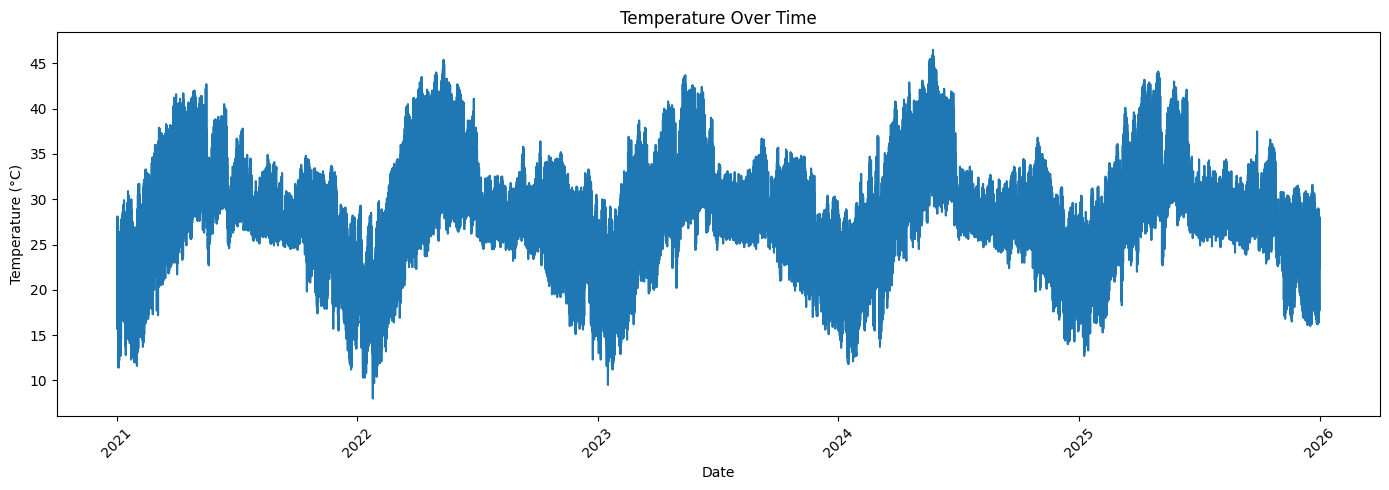

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["temperature_2m (°C)"])

plt.title("Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

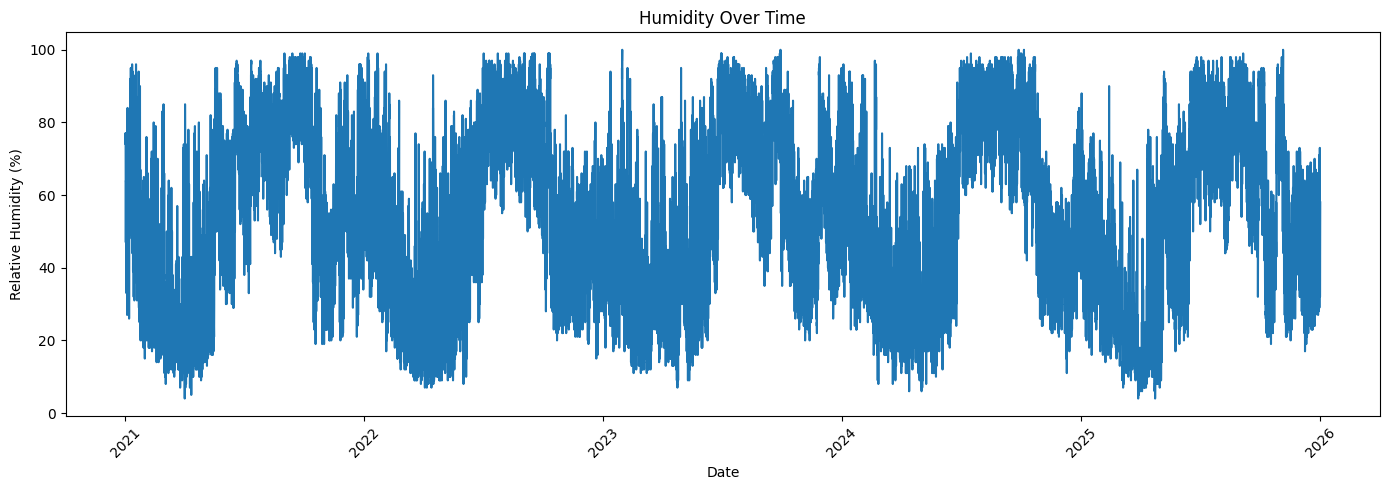

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["relative_humidity_2m (%)"])

plt.title("Humidity Over Time")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the weather dataset through statistical summaries and visualizations. In this section, temperature, relative humidity, and precipitation are plotted over time to observe their variations and identify possible weather patterns.

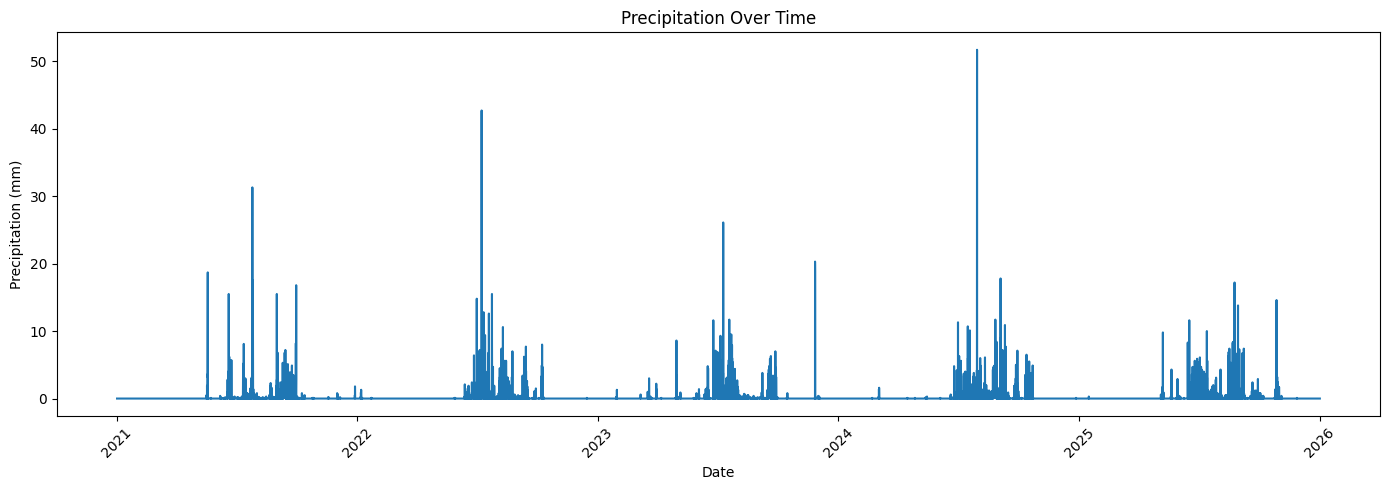

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["precipitation (mm)"])

plt.title("Precipitation Over Time")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [19]:
df["weather_code (wmo code)"].value_counts().sort_index()

weather_code (wmo code)
0.0     24875
1.0      3312
2.0      2019
3.0      8065
51.0     3582
53.0      654
55.0      209
61.0      507
63.0      512
65.0       89
Name: count, dtype: int64

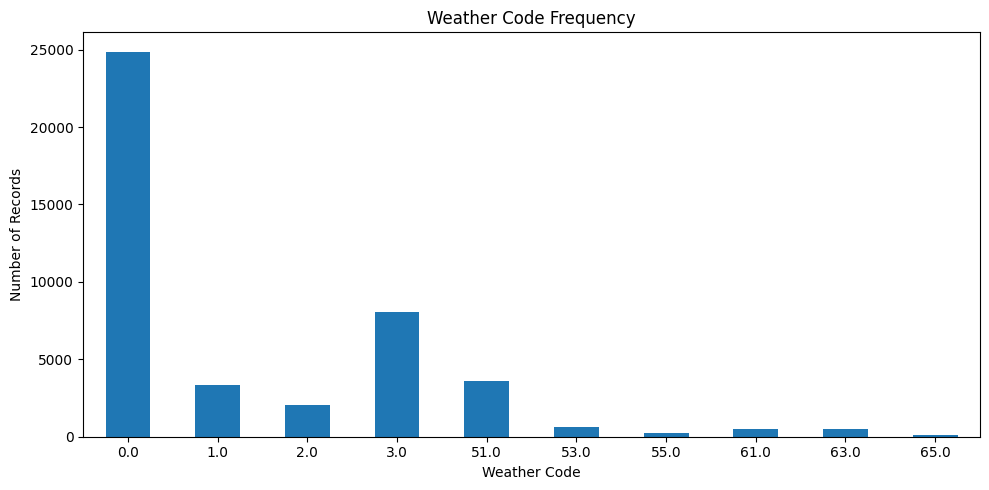

In [20]:
plt.figure(figsize=(10, 5))

df["weather_code (wmo code)"].value_counts().sort_index().plot(kind="bar")

plt.title("Weather Code Frequency")
plt.xlabel("Weather Code")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [21]:
weather_mapping = {
    0: "Clear",
    1: "Mainly Clear",
    2: "Partly Cloudy",
    3: "Overcast",
    51: "Drizzle",
    53: "Drizzle",
    55: "Drizzle",
    61: "Rain",
    63: "Rain",
    65: "Rain"
}

df["weather_condition"] = df["weather_code (wmo code)"].map(weather_mapping)

df[["weather_code (wmo code)", "weather_condition"]].drop_duplicates().sort_values(
    "weather_code (wmo code)"
)

,weather_code (wmo code),weather_condition
0,0.0,Clear
17,1.0,Mainly Clear
30,2.0,Partly Cloudy
34,3.0,Overcast
3258,51.0,Drizzle
3259,53.0,Drizzle
4027,55.0,Drizzle
3278,61.0,Rain
3293,63.0,Rain
3302,65.0,Rain


In [22]:
df["weather_condition"].value_counts()

weather_condition
Clear            24875
Overcast          8065
Drizzle           4445
Mainly Clear      3312
Partly Cloudy     2019
Rain              1108
Name: count, dtype: int64

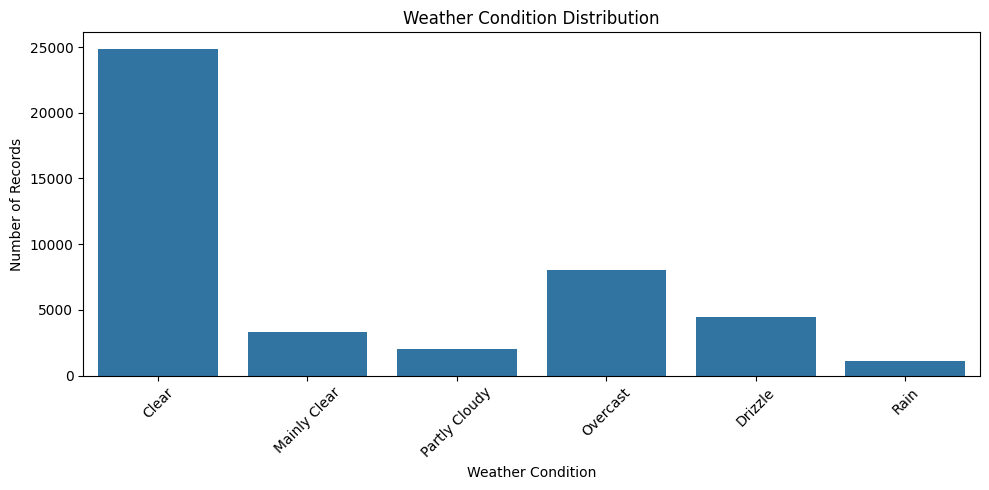

In [23]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="weather_condition")

plt.title("Weather Condition Distribution")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

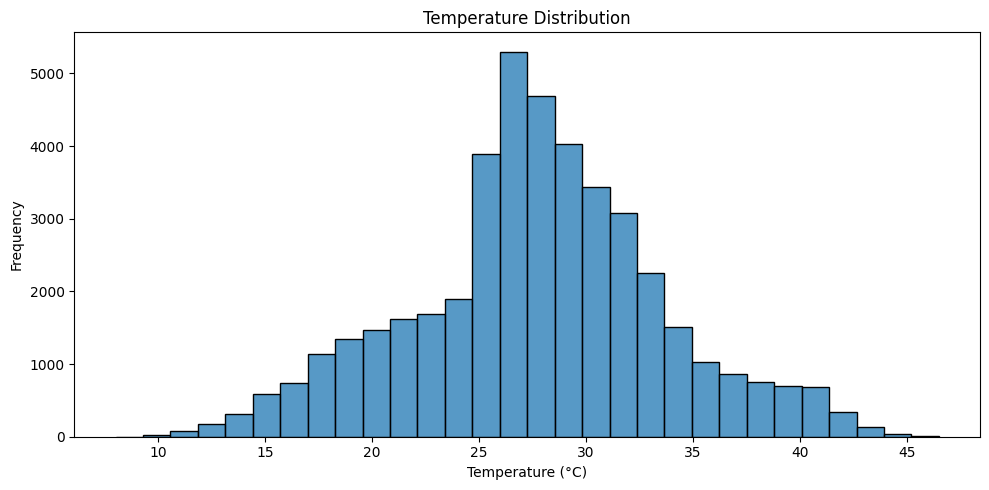

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="temperature_2m (°C)", bins=30, kde=False)

plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

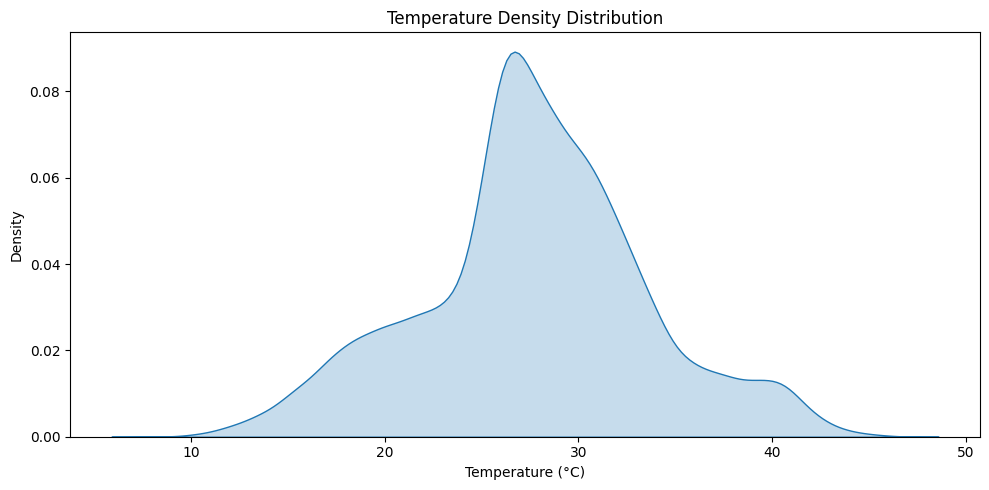

In [25]:
plt.figure(figsize=(10, 5))

sns.kdeplot(data=df, x="temperature_2m (°C)", fill=True)

plt.title("Temperature Density Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Density")
plt.tight_layout()

plt.show()

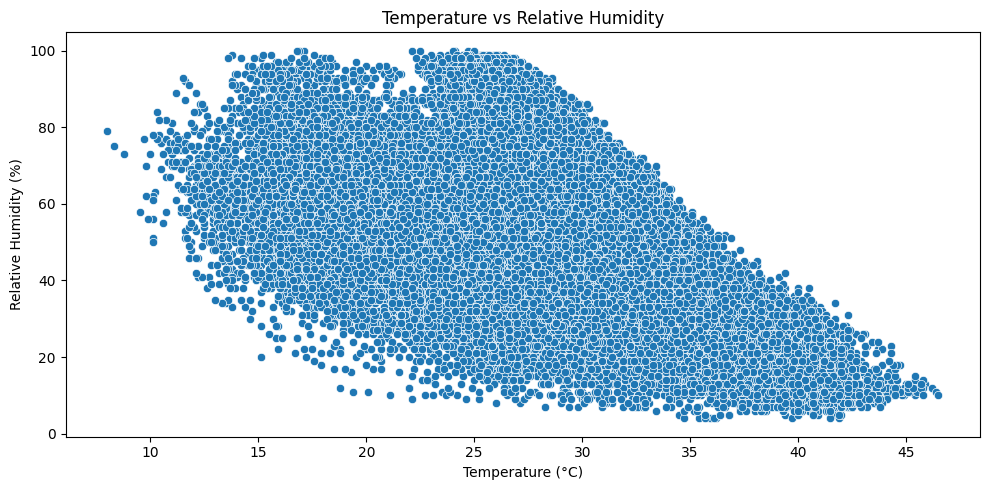

In [26]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="temperature_2m (°C)",
    y="relative_humidity_2m (%)"
)

plt.title("Temperature vs Relative Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Relative Humidity (%)")
plt.tight_layout()

plt.show()

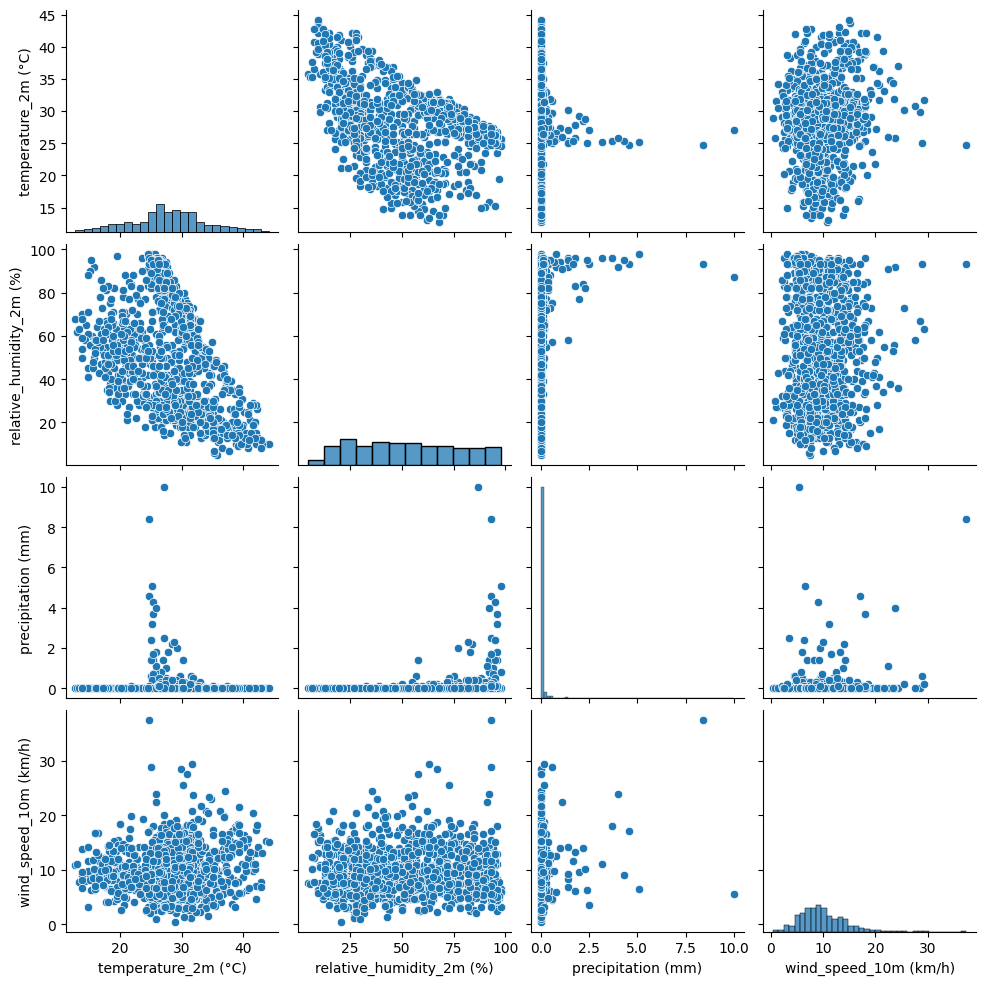

In [27]:
sns.pairplot(
    df[
        [
            "temperature_2m (°C)",
            "relative_humidity_2m (%)",
            "precipitation (mm)",
            "wind_speed_10m (km/h)"
        ]
    ].sample(n=min(1000, len(df)), random_state=42)
)

plt.show()

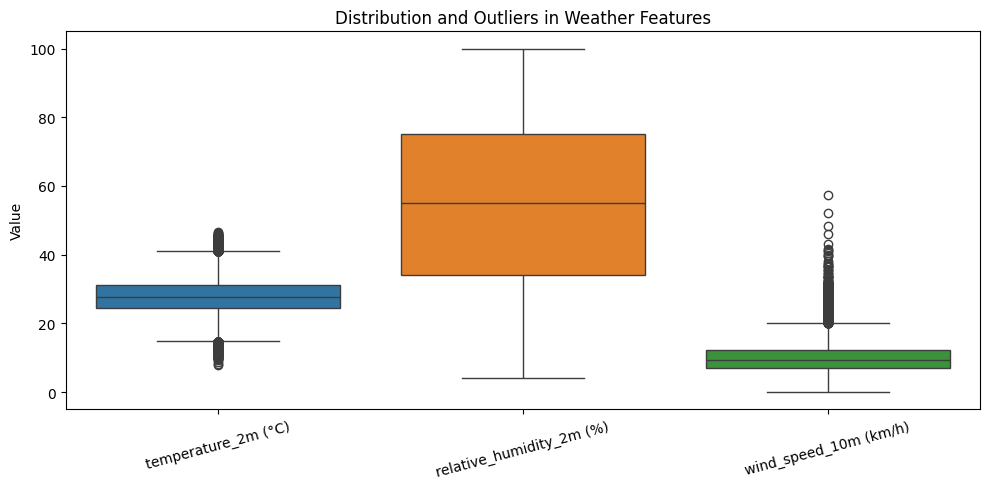

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df[
        [
            "temperature_2m (°C)",
            "relative_humidity_2m (%)",
            "wind_speed_10m (km/h)"
        ]
    ]
)

plt.title("Distribution and Outliers in Weather Features")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

## 5. Daily Weather Data Preparation

The hourly weather observations are aggregated into daily records to prepare the dataset for machine learning. Daily averages are calculated for selected weather measurements, daily precipitation is summed, and the most frequent weather condition is selected for each day.

In [29]:
daily_df = df.copy()

daily_df["date"] = daily_df["time"].dt.date

daily_df = daily_df.groupby("date").agg({
    "temperature_2m (°C)": "mean",
    "relative_humidity_2m (%)": "mean",
    "precipitation (mm)": "sum",
    "surface_pressure (hPa)": "mean",
    "cloud_cover (%)": "mean",
    "wind_speed_10m (km/h)": "mean",
    "weather_condition": lambda x: x.mode()[0]
}).reset_index()

daily_df.head()

,date,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition
0,2021-01-01,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear
1,2021-01-02,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear
2,2021-01-03,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear
3,2021-01-04,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear
4,2021-01-05,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear


In [30]:
daily_df.shape

(1826, 8)

In [31]:
daily_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      1826 non-null   object 
 1   temperature_2m (°C)       1826 non-null   float64
 2   relative_humidity_2m (%)  1826 non-null   float64
 3   precipitation (mm)        1826 non-null   float64
 4   surface_pressure (hPa)    1826 non-null   float64
 5   cloud_cover (%)           1826 non-null   float64
 6   wind_speed_10m (km/h)     1826 non-null   float64
 7   weather_condition         1826 non-null   object 
dtypes: float64(6), object(2)
memory usage: 114.3+ KB


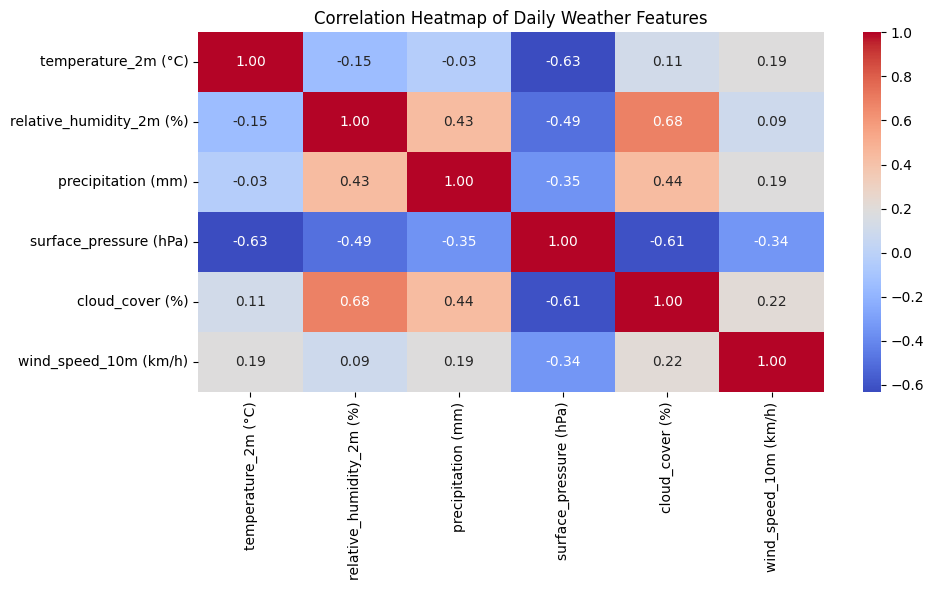

In [32]:
plt.figure(figsize=(10, 6))

numeric_df = daily_df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Daily Weather Features")
plt.tight_layout()

plt.show()

### 5.1 Creating the Target Variable

The target variable represents the weather condition for the following day. The `shift(-1)` operation moves the next day's weather condition into the current day's record, allowing the machine learning models to learn from the current day's weather measurements and predict the next day's weather category.

In [33]:
daily_df["date"] = pd.to_datetime(daily_df["date"])

daily_df["tomorrow_weather"] = daily_df["weather_condition"].shift(-1)

daily_df.head()

,date,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,tomorrow_weather
0,2021-01-01,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear,Clear
1,2021-01-02,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear,Clear
2,2021-01-03,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear,Clear
3,2021-01-04,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear,Clear
4,2021-01-05,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear,Clear


In [34]:
daily_df["tomorrow_weather"].value_counts()

tomorrow_weather
Clear            1177
Overcast          376
Drizzle           202
Mainly Clear       41
Rain               20
Partly Cloudy       9
Name: count, dtype: int64

In [35]:
target_mapping = {
    "Clear": "Clear",
    "Mainly Clear": "Clear",
    "Partly Cloudy": "Cloudy",
    "Overcast": "Cloudy",
    "Drizzle": "Rainy",
    "Rain": "Rainy"
}

daily_df["tomorrow_weather_class"] = daily_df["tomorrow_weather"].map(target_mapping)

daily_df["tomorrow_weather_class"].value_counts()

tomorrow_weather_class
Clear     1218
Cloudy     385
Rainy      222
Name: count, dtype: int64

In [36]:
daily_df = daily_df.dropna(subset=["tomorrow_weather_class"]).copy()

daily_df.shape

(1825, 10)

In [37]:
daily_df.to_csv("../data/daily_weather_dataset.csv", index=False)

# Phase 3: Model Building

This phase prepares the features and target variable, splits the dataset into training and testing sets, preprocesses the data, trains multiple machine learning models, and saves the best-performing model.

### 5.2 Feature Selection and Target Separation

The dataset is divided into input features and a target variable. The input features include daily weather measurements, the existing weather condition, and the month. The target variable is `tomorrow_weather_class`, which represents the weather category to be predicted for the following day.

In [38]:
daily_df["month"] = daily_df["date"].dt.month

X = daily_df[
    [
        "temperature_2m (°C)",
        "relative_humidity_2m (%)",
        "precipitation (mm)",
        "surface_pressure (hPa)",
        "cloud_cover (%)",
        "wind_speed_10m (km/h)",
        "weather_condition",
        "month"
    ]
]

y = daily_df["tomorrow_weather_class"]

X.head()

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear,1
1,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear,1
2,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear,1
3,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear,1
4,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear,1


### 5.3 Train-Test Split

The dataset is divided chronologically into 80% training data and 20% testing data. The training set contains 1,460 samples from January 2021 to December 2024, while the testing set contains 365 samples from the year 2025. This approach evaluates the models on later observations while preserving the time order of the weather data.

In [39]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", daily_df["date"].iloc[0], "to", daily_df["date"].iloc[split_index - 1])
print("Testing period:", daily_df["date"].iloc[split_index], "to", daily_df["date"].iloc[-1])

Training samples: 1460
Testing samples: 365
Training period: 2021-01-01 00:00:00 to 2024-12-30 00:00:00
Testing period: 2024-12-31 00:00:00 to 2025-12-30 00:00:00


### 5.4 Data Preprocessing

Data preprocessing prepares the input features for machine learning. StandardScaler is used to standardize numerical features, while OneHotEncoder converts the categorical weather condition into a numerical representation. The ColumnTransformer applies the appropriate preprocessing method to each type of feature.

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "temperature_2m (°C)",
    "relative_humidity_2m (%)",
    "precipitation (mm)",
    "surface_pressure (hPa)",
    "cloud_cover (%)",
    "wind_speed_10m (km/h)",
    "month"
]

categorical_features = ["weather_condition"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 6. Model Building and Training

Three machine learning classification algorithms are used to predict the next day's weather condition: Logistic Regression, Decision Tree, and Random Forest. Each model is trained using the training dataset and evaluated on the testing dataset to compare its prediction performance.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("All 3 models created successfully.")

All 3 models created successfully.


In [42]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("All 3 models trained successfully.")

All 3 models trained successfully.


# Phase 2: Evaluation Metrics

This phase evaluates the trained machine learning models using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix to compare their performance.

### 6.1 Model Evaluation and Performance Comparison

The trained models are evaluated using Accuracy, Precision, Recall, and F1-Score. These metrics help compare the models' performance on the testing dataset and identify the most suitable model for weather prediction.

In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.775342,0.770059,0.775342,0.768496
1,Decision Tree,0.687671,0.717363,0.687671,0.700192
2,Random Forest,0.794521,0.787364,0.794521,0.784718


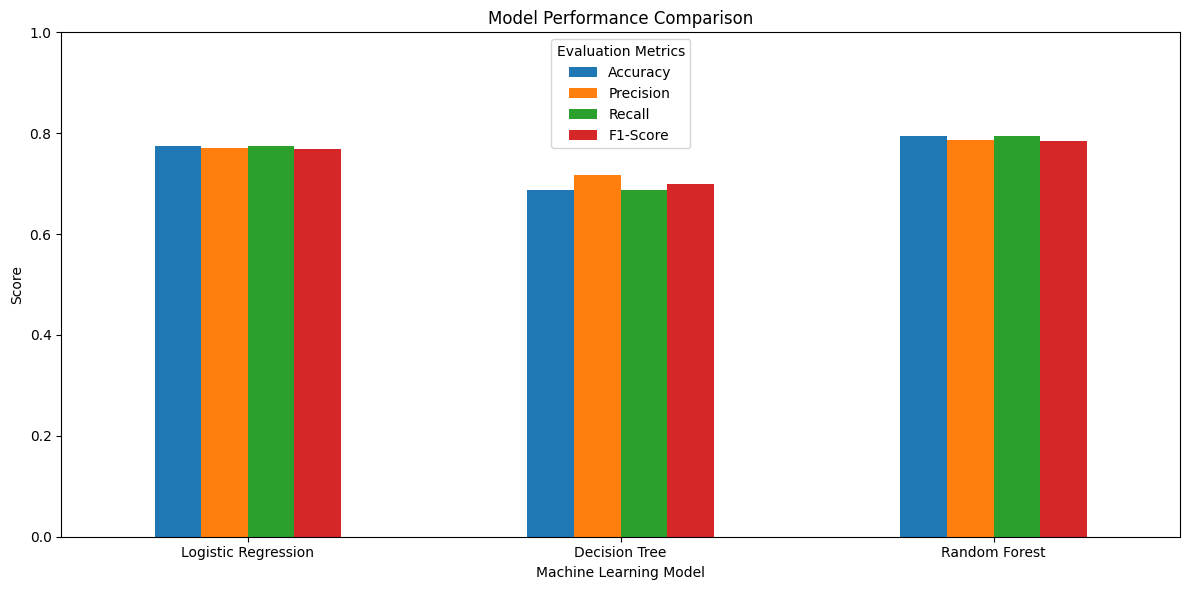

In [44]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()

plt.show()

### 6.2 Confusion Matrix Analysis

A confusion matrix compares the actual weather categories with the categories predicted by each machine learning model. It helps identify correct predictions and cases where the model misclassifies Clear, Cloudy, or Rainy weather.


Logistic Regression
[[223  16   1]
 [ 20  30  30]
 [  3  12  30]]


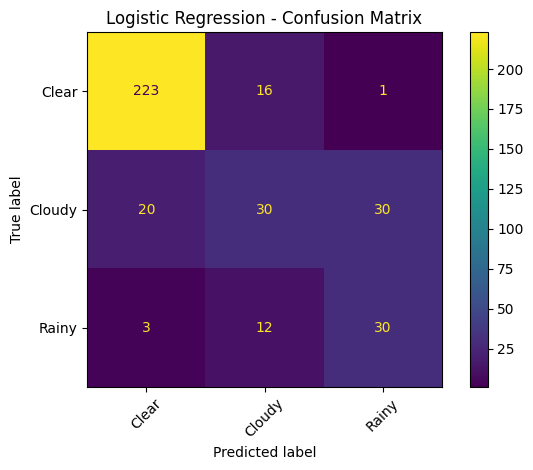


Decision Tree
[[198  41   1]
 [ 20  28  32]
 [  1  19  25]]


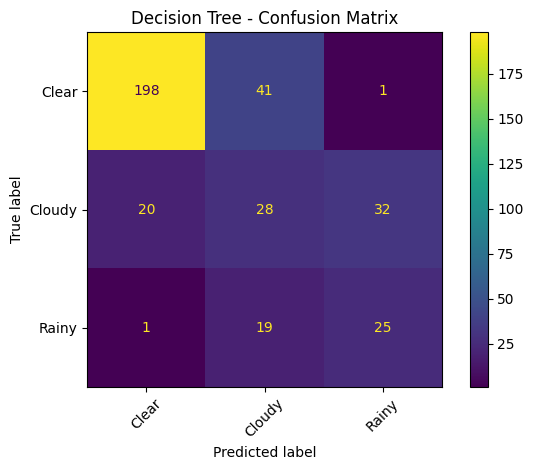


Random Forest
[[229  10   1]
 [ 20  31  29]
 [  3  12  30]]


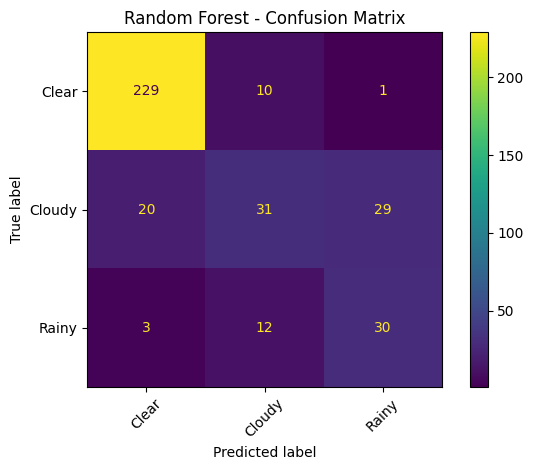

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n{name}")
    print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )
    
    disp.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 6.3 Best Model Selection

The performance comparison shows that Random Forest achieved the highest accuracy among the three models, with approximately **79.45%** accuracy on the test dataset. Therefore, Random Forest is selected as the final model for predicting the next day's weather category.

In [38]:
import joblib

final_model = trained_models["Random Forest"]

joblib.dump(
    final_model,
    "../models/weather_random_forest.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [39]:
import requests

location = "Ahmedabad"

url = "https://geocoding-api.open-meteo.com/v1/search"

params = {
    "name": location,
    "count": 1,
    "language": "en",
    "format": "json"
}

response = requests.get(url, params=params)

response.json()

{'results': [{'id': 1279233,
   'name': 'Ahmedabad',
   'latitude': 23.02579,
   'longitude': 72.58727,
   'elevation': 56.0,
   'feature_code': 'PPL',
   'country_code': 'IN',
   'admin1_id': 1270770,
   'admin2_id': 1279234,
   'admin3_id': 12684092,
   'timezone': 'Asia/Kolkata',
   'population': 6357693,
   'country_id': 1269750,
   'country': 'India',
   'admin1': 'Gujarat',
   'admin2': 'Ahmadābād District',
   'admin3': 'Sabarmati'}],
 'generationtime_ms': 0.1180172}

In [40]:
# Get today's weather data for the selected location

latitude = response.json()["results"][0]["latitude"]
longitude = response.json()["results"][0]["longitude"]

weather_url = "https://api.open-meteo.com/v1/forecast"

weather_params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "weather_code",
        "surface_pressure",
        "cloud_cover",
        "wind_speed_10m"
    ],
    "forecast_days": 1,
    "timezone": "auto"
}

weather_response = requests.get(weather_url, params=weather_params)

weather_response.json()

{'latitude': 23.022846,
 'longitude': 72.60188,
 'generationtime_ms': 0.17642974853515625,
 'utc_offset_seconds': 19800,
 'timezone': 'Asia/Kolkata',
 'timezone_abbreviation': 'GMT+5:30',
 'elevation': 53.0,
 'hourly_units': {'time': 'iso8601',
  'temperature_2m': '°C',
  'relative_humidity_2m': '%',
  'precipitation': 'mm',
  'weather_code': 'wmo code',
  'surface_pressure': 'hPa',
  'cloud_cover': '%',
  'wind_speed_10m': 'km/h'},
 'hourly': {'time': ['2026-10-28T00:00',
   '2026-10-28T01:00',
   '2026-10-28T02:00',
   '2026-10-28T03:00',
   '2026-10-28T04:00',
   '2026-10-28T05:00',
   '2026-10-28T06:00',
   '2026-10-28T07:00',
   '2026-10-28T08:00',
   '2026-10-28T09:00',
   '2026-10-28T10:00',
   '2026-10-28T11:00',
   '2026-10-28T12:00',
   '2026-10-28T13:00',
   '2026-10-28T14:00',
   '2026-10-28T15:00',
   '2026-10-28T16:00',
   '2026-10-28T17:00',
   '2026-10-28T18:00',
   '2026-10-28T19:00',
   '2026-10-28T20:00',
   '2026-10-28T21:00',
   '2026-10-28T22:00',
   '2026-10-28T2

In [41]:
import pandas as pd

# Get hourly weather data
hourly_data = weather_response.json()["hourly"]

# Create DataFrame
today_df = pd.DataFrame(hourly_data)

# Convert time column to datetime
today_df["time"] = pd.to_datetime(today_df["time"])

# Calculate today's daily weather features
today_features = pd.DataFrame({
    "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
    "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
    "precipitation (mm)": [today_df["precipitation"].sum()],
    "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
    "cloud_cover (%)": [today_df["cloud_cover"].mean()],
    "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
})

# Convert weather codes into our training conditions
def weather_condition(code):
    if code == 0:
        return "Clear"
    elif code == 1:
        return "Mainly Clear"
    elif code == 2:
        return "Partly Cloudy"
    elif code == 3:
        return "Overcast"
    elif code in [51, 53, 55]:
        return "Drizzle"
    elif code in [61, 63, 65]:
        return "Rain"
    else:
        return "Clear"

# Find the most common weather condition today
today_conditions = today_df["weather_code"].apply(weather_condition)
today_features["weather_condition"] = today_conditions.mode()[0]

# Add month
today_features["month"] = today_df["time"].dt.month.iloc[0]

today_features

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,29.420833,29.166667,0.0,1006.416667,1.208333,10.458333,Clear,10


In [42]:
import joblib

# Load the trained Random Forest model
final_model = joblib.load("../models/weather_random_forest.pkl")

print("Random Forest model loaded successfully.")

Random Forest model loaded successfully.


In [43]:
# Predict tomorrow's weather condition

prediction = final_model.predict(today_features)

print("Predicted weather for tomorrow:", prediction[0])

Predicted weather for tomorrow: Clear


In [44]:
# Get prediction probabilities

probabilities = final_model.predict_proba(today_features)

confidence = probabilities.max() * 100

print("Predicted weather for tomorrow:", prediction[0])
print("Prediction confidence:", round(confidence, 2), "%")

Predicted weather for tomorrow: Clear
Prediction confidence: 96.0 %


# Phase 4: Advanced Techniques

This phase integrates live weather data through an API, accepts user-selected locations, predicts the next day's weather, calculates prediction confidence, and tests the system with different locations.

## 7. Live Weather Data Retrieval

The Open-Meteo API is used to retrieve current weather data for the selected location. The location is first converted into geographical coordinates using the geocoding API. These coordinates are then used to fetch hourly weather measurements required for prediction.

In [46]:
# Test user location input

user_location = input("Enter location: ")

print("Selected location:", user_location)


Enter location:  Pune


Selected location: Pune


In [47]:
# Convert user location into latitude and longitude

geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

geocoding_params = {
    "name": user_location,
    "count": 1,
    "language": "en",
    "format": "json"
}

geocoding_response = requests.get(
    geocoding_url,
    params=geocoding_params
)

location_data = geocoding_response.json()

latitude = location_data["results"][0]["latitude"]
longitude = location_data["results"][0]["longitude"]

print("Location:", location_data["results"][0]["name"])
print("Latitude:", latitude)
print("Longitude:", longitude)

Location: Pune
Latitude: 18.51957
Longitude: 73.85535


In [48]:
# Get today's weather for the user's location

weather_url = "https://api.open-meteo.com/v1/forecast"

weather_params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "weather_code",
        "surface_pressure",
        "cloud_cover",
        "wind_speed_10m"
    ],
    "forecast_days": 1,
    "timezone": "auto"
}

weather_response = requests.get(
    weather_url,
    params=weather_params
)

print("Weather data received successfully.")

Weather data received successfully.


### 7.1 Preparing Live Weather Data

The retrieved hourly weather data is converted into daily features to match the format used during model training. Daily averages are calculated for temperature, relative humidity, surface pressure, cloud cover, and wind speed, while daily precipitation is summed. The most frequent weather condition and the month are also included as input features.

In [49]:
# Convert hourly weather data into daily features

hourly_data = weather_response.json()["hourly"]

today_df = pd.DataFrame(hourly_data)

today_df["time"] = pd.to_datetime(today_df["time"])


today_features = pd.DataFrame({
    "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
    "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
    "precipitation (mm)": [today_df["precipitation"].sum()],
    "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
    "cloud_cover (%)": [today_df["cloud_cover"].mean()],
    "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
})


today_conditions = today_df["weather_code"].apply(weather_condition)

today_features["weather_condition"] = today_conditions.mode()[0]

today_features["month"] = today_df["time"].dt.month.iloc[0]


today_features

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,26.133333,42.625,0.0,949.541667,60.0,8.720833,Partly Cloudy,10


In [50]:
# Predict tomorrow's weather for the selected location

prediction = final_model.predict(today_features)

probabilities = final_model.predict_proba(today_features)

confidence = probabilities.max() * 100

print("Location:", location_data["results"][0]["name"])
print("Predicted weather for tomorrow:", prediction[0])
print("Prediction confidence:", round(confidence, 2), "%")

Location: Pune
Predicted weather for tomorrow: Clear
Prediction confidence: 48.0 %


### 7.2 Predicting the Next Day's Weather

The trained Random Forest model uses the prepared weather features to predict the next day's weather category. The model also calculates prediction probabilities, from which the highest probability is displayed as the prediction confidence. A reusable function allows the prediction process to be performed for different user-specified locations.

In [51]:
def predict_weather(location):

    # 1. Convert location to coordinates
    geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

    geocoding_params = {
        "name": location,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    geocoding_response = requests.get(
        geocoding_url,
        params=geocoding_params
    )

    location_data = geocoding_response.json()

    if "results" not in location_data:
        print("Location not found.")
        return

    latitude = location_data["results"][0]["latitude"]
    longitude = location_data["results"][0]["longitude"]
    location_name = location_data["results"][0]["name"]


    # 2. Get today's weather
    weather_url = "https://api.open-meteo.com/v1/forecast"

    weather_params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "weather_code",
            "surface_pressure",
            "cloud_cover",
            "wind_speed_10m"
        ],
        "forecast_days": 1,
        "timezone": "auto"
    }

    weather_response = requests.get(
        weather_url,
        params=weather_params
    )

    hourly_data = weather_response.json()["hourly"]


    # 3. Convert hourly data to daily features
    today_df = pd.DataFrame(hourly_data)

    today_df["time"] = pd.to_datetime(today_df["time"])

    today_features = pd.DataFrame({
        "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
        "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
        "precipitation (mm)": [today_df["precipitation"].sum()],
        "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
        "cloud_cover (%)": [today_df["cloud_cover"].mean()],
        "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
    })

    today_conditions = today_df["weather_code"].apply(weather_condition)

    today_features["weather_condition"] = today_conditions.mode()[0]

    today_features["month"] = today_df["time"].dt.month.iloc[0]


    # 4. Make prediction
    prediction = final_model.predict(today_features)

    probabilities = final_model.predict_proba(today_features)

    confidence = probabilities.max() * 100


    # 5. Display result
    print("Location:", location_name)
    print("Predicted weather for tomorrow:", prediction[0])
    print("Prediction confidence:", round(confidence, 2), "%")

### 7.3 Testing Predictions for Different Locations

The reusable prediction function is tested with different location inputs. A valid location retrieves the weather data and displays the predicted weather category for the next day along with its prediction confidence. An invalid location is handled by displaying a message indicating that the location was not found.

In [52]:
predict_weather("Delhi")

Location: Delhi
Predicted weather for tomorrow: Clear
Prediction confidence: 64.0 %


In [53]:
predict_weather("XYZ12345")

Location not found.


In [54]:
# Test user location input

user_location = input("Enter location: ")

print("Selected location:", user_location)

predict_weather(user_location)

Enter location:  Ahmedabad


Selected location: Ahmedabad
Location: Ahmedabad
Predicted weather for tomorrow: Clear
Prediction confidence: 96.0 %
